<a href="https://colab.research.google.com/github/recxdivist/ocean_lab/blob/main/Lab01_oxygen.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab01 - sprint 1
## Random Variable 01: растворённый кислород (O2ml_L)
### Description

Мы рассматриваем датасет CalCOFI: океанографические наблюдения у берегов Калифорнии, которые ведутся с 1949 года. В нём для каждой пробы воды записано много характеристик: температура, солёность, глубина и другие. В своей части работы я исследую растворённый в воде кислород в мл/л (O2ml_L). Воду отбирают на кораблях с помощью бутылок Нискина (труб с крышками на обоих концах) на разных глубинах, потом титруют по Винклеру прямо на судне.
Значение получается случайным, так как на него влияет множество факторов: время года, погодные условия, состояние воды, год измерения, количество планктона и так далее. Одна строка датасета соответствует одной пробе.

In [1]:
import kagglehub
path = kagglehub.dataset_download("sohier/calcofi")
print(path)

import os
print(os.listdir(path))

Using Colab cache for faster access to the 'calcofi' dataset.
/kaggle/input/calcofi
['bottle.csv', 'cast.csv']


In [2]:
import pandas as pd

df = pd.read_csv(path + "/bottle.csv", encoding="latin-1", low_memory=False)
print("Строк и столбцов:", df.shape)

oxygen = df["O2ml_L"]
print("Пропусков в кислороде:", oxygen.isna().sum())
print(oxygen.head(10))


Строк и столбцов: (864863, 74)
Пропусков в кислороде: 168662
0   NaN
1   NaN
2   NaN
3   NaN
4   NaN
5   NaN
6   NaN
7   NaN
8   NaN
9   NaN
Name: O2ml_L, dtype: float64


In [3]:
oxygen = oxygen.dropna()
print("Осталось значений:", len(oxygen))
print(oxygen.describe())

Осталось значений: 696201
count    696201.000000
mean          3.392468
std           2.073256
min          -0.010000
25%           1.360000
50%           3.440000
75%           5.500000
max          11.130000
Name: O2ml_L, dtype: float64


В столбце O2ml_L было 168 662 пропуска из 864 863 строк, то есть примерно 19,5 %. Скорее всего, в этих пробах кислород просто не измеряли. Восстановить пропущенные значения нельзя: если заполнить их, например, средним, распределение бы исказилось, выводы были бы неверными. Поэтому мы удалили пропуски. Осталось 696 201 значение, этого более чем достаточно для анализа.

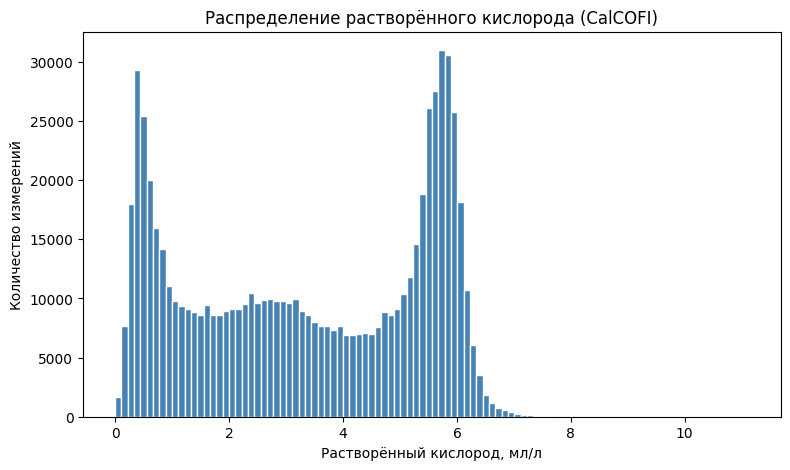

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.hist(oxygen, bins=100, color="steelblue", edgecolor="white")
plt.xlabel("Растворённый кислород, мл/л")
plt.ylabel("Количество измерений")
plt.title("Распределение растворённого кислорода (CalCOFI)")
plt.show()


#### Проверка случайной природы величины

In [5]:
o2_100 = df.loc[df["Depthm"] == 100, "O2ml_L"].dropna()
print("Число измерений на глубине 100 м:", len(o2_100))
print(o2_100.describe())

Число измерений на глубине 100 м: 22096
count    22096.000000
mean         4.135426
std          1.228856
min          0.060000
25%          3.230000
50%          4.150000
75%          5.260000
max          6.930000
Name: O2ml_L, dtype: float64


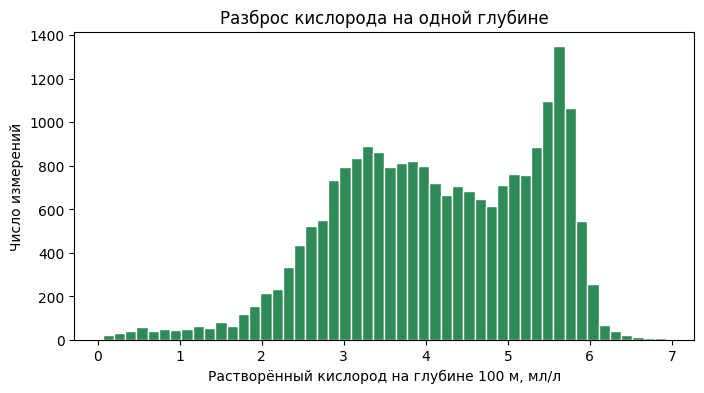

In [6]:
plt.figure(figsize=(8, 4))
plt.hist(o2_100, bins=50, color="seagreen", edgecolor="white")
plt.xlabel("Растворённый кислород на глубине 100 м, мл/л")
plt.ylabel("Число измерений")
plt.title("Разброс кислорода на одной глубине")
plt.show()


Мы взяли измерения на одной глубине (100 м). Всего таких измерений оказалось 22096. Минимальное значение - 0,06 мл/л, максимальное - 6,93 мл/л. Среднее значение - 4,14 мл/л, std = 1,23 мл/л. Половина значений находится между 3,23 и 5,26 мл/л.
Если бы кислород был функцией, зависящей только от глубины, все значения на одной глубине были бы одинаковыми, минимум был бы равен максимуму, разброс (std) был бы равен 0, а на гистограмме был бы только один столбик. На деле значения растворённого кислорода на одной глубине сильно различаются (от 0,06 до 6,93 мл/л), std = 1,23 мл/л, то есть отличен от нуля, а гистограмма состоит из множества столбиков. Значит, растворённый кислород не определяется одной лишь глубиной.
Разброс объясняется тем, что кислород зависит не только от глубины, но и от времени года, когда бралась проба, от места станции и года измерения, от состояния океана (течения, подъём глубинных вод), от количества планктона, который поглощает и выделяет кислород.
Таким образом, мы сделали вывод, что кислород - это случайная величина: его значение в отдельном измерении нельзя заранее точно предсказать, даже зная глубину.

### EDA & Distribution

In [7]:
oxy = df["O2ml_L"].dropna()

stats = {
    "Количество": len(oxy),
    "Среднее": oxy.mean(),
    "Медиана": oxy.median(),
    "Стандартное отклонение": oxy.std(),
    "Минимум": oxy.min(),
    "Q1 (25%)": oxy.quantile(0.25),
    "Q3 (75%)": oxy.quantile(0.75),
    "Максимум": oxy.max(),
    "Размах": oxy.max() - oxy.min(),
    "IQR (Q3 − Q1)": oxy.quantile(0.75) - oxy.quantile(0.25),
    "Асимметрия": oxy.skew(),
    "Эксцесс": oxy.kurt(),
}
pd.Series(stats).round(3)

,0
Количество,696201.000
Среднее,3.392
Медиана,3.440
Стандартное отклонение,2.073
Минимум,-0.010
Q1 (25%),1.360
Q3 (75%),5.500
Максимум,11.130
Размах,11.140
IQR (Q3 − Q1),4.140


Отрицательных значений: 4 (0.0006 % от всех)
Самые маленькие значения: [np.float64(-0.01), np.float64(0.0), np.float64(0.001), np.float64(0.002), np.float64(0.006)]


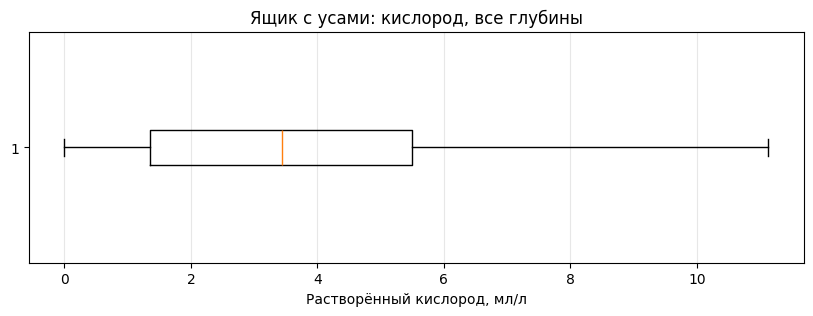

In [8]:
import matplotlib.pyplot as plt

neg = (oxy < 0).sum()
print("Отрицательных значений:", neg, f"({neg / len(oxy) * 100:.4f} % от всех)")
print("Самые маленькие значения:", sorted(oxy.unique())[:5])

plt.figure(figsize=(10, 3))
plt.boxplot(oxy, vert=False, whis=1.5)
plt.xlabel("Растворённый кислород, мл/л")
plt.title("Ящик с усами: кислород, все глубины")
plt.grid(axis="x", alpha=0.3)
plt.show()

Вывод по EDA:
средние 50 % измерений кислорода лежат в диапазоне от 1,36 до 5,50 мл/л (IQR = 4,14 мл/л). Медиана (3,44 мл/л) находится почти точно в середине ящика, что вместе с коэффициентом асимметрии −0,12 говорит о почти симметричном распределении.
Выбросов по правилу 1,5×IQR нет: границы составляют от −4,85 до 11,71 мл/л, и все значения попадают внутрь.
Найдено 4 отрицательных значения (0,0006 % от всех, минимум −0,01 мл/л). Физически кислород не может быть отрицательным, поэтому это погрешность метода Винклера при очень низких концентрациях. Из-за их малого количества они не влияют на статистику, и мы оставляем их в данных.
При этом ящик с усами не показывает бимодальность, которая хорошо видна на гистограмме: он накрывает провал между пиками около 0,5 и 5,8 мл/л. Поэтому форму распределения нужно оценивать по гистограмме, а ящик с усами использовать для анализа разброса и выбросов.

### Independence & Estimations

In [9]:
import numpy as np

oxygen = df['O2ml_L'].dropna()
print("Настоящее среднее:", round(oxygen.mean(), 3))
print("Настоящая дисперсия:", round(oxygen.var(), 3))

for n in [10, 100, 1000, 10000, 100000]:
    sample = oxygen.sample(n=n, random_state=1)
    print(n, round(sample.mean(), 3), round(sample.var(), 3))

Настоящее среднее: 3.392
Настоящая дисперсия: 4.298
10 4.175 2.386
100 3.344 4.55
1000 3.454 4.236
10000 3.383 4.313
100000 3.386 4.304


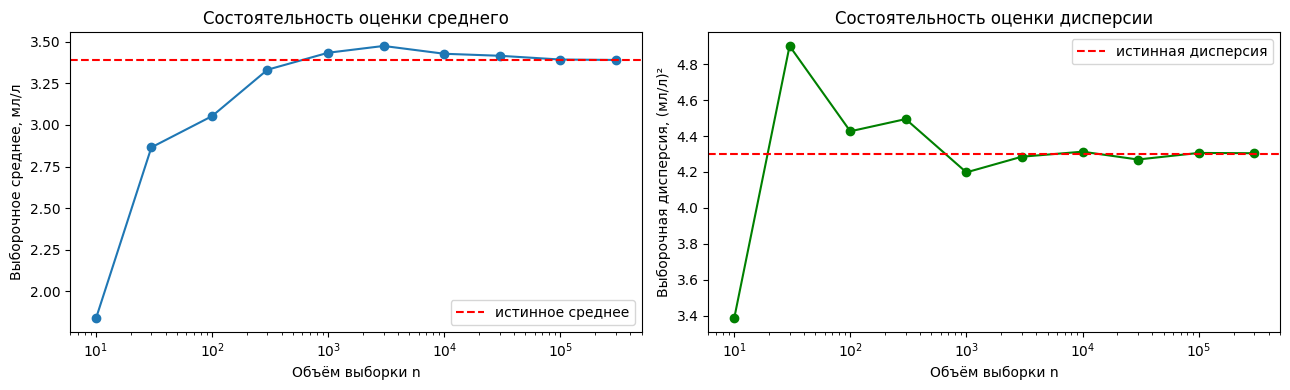

In [10]:
import matplotlib.pyplot as plt

sizes = [10, 30, 100, 300, 1000, 3000, 10000, 30000, 100000, 300000]
means = []
variances = []

for n in sizes:
    sample = oxygen.sample(n=n, random_state=42)
    means.append(sample.mean())
    variances.append(sample.var())

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

ax[0].plot(sizes, means, marker="o")
ax[0].axhline(oxygen.mean(), color="red", linestyle="--", label="истинное среднее")
ax[0].set_xscale("log")
ax[0].set_xlabel("Объём выборки n")
ax[0].set_ylabel("Выборочное среднее, мл/л")
ax[0].set_title("Состоятельность оценки среднего")
ax[0].legend()

ax[1].plot(sizes, variances, marker="o", color="green")
ax[1].axhline(oxygen.var(), color="red", linestyle="--", label="истинная дисперсия")
ax[1].set_xscale("log")
ax[1].set_xlabel("Объём выборки n")
ax[1].set_ylabel("Выборочная дисперсия, (мл/л)²")
ax[1].set_title("Состоятельность оценки дисперсии")
ax[1].legend()

plt.tight_layout()
plt.show()

Вывод по состоятельности оценок: при малых объёмах выборки (n = 10, 30) выборочное среднее сильно отклоняется от истинного: при n = 10 оно составило около 1,9 мл/л против настоящих 3,39 мл/л. С ростом n точки на графике подходят к красной линии всё ближе, и начиная примерно с n = 10 000 отличие от истинного значения становится небольшим. То же самое происходит с выборочной дисперсией: с ростом n она приближается к истинному значению 4,30 (мл/л)². Приближение не всегда идёт ровно, то есть, не является монотонным. Например, при n = 1000 выборочное среднее (3,454) оказалось дальше от истинного, чем при n = 100 (3,344). Это не противоречит состоятельности, потому что она обещает приближение к истинному значению при больших n, а не то, что при каждом шаге у нас будет более точное значение. При малых n отклонения будут очень большими. Это объясняется большим разбросом кислорода и бимодальным распределением: в маленькую выборку могут попасть в основном измерения на большой глубине с низким содержанием кислорода, и тогда среднее окажется сильно заниженным. Таким образом, выборочное среднее и выборочная дисперсия - состоятельные оценки: чтобы судить о генеральной совокупности, не обязательно измерять все 696 201 значения, достаточно выборки в несколько десятков тысяч измерений.

### Normalization

Исходные данные:   min = -0.01  max = 11.13  среднее = 3.392  std = 2.073
После min-max:     min = 0.0  max = 1.0  среднее = 0.305  std = 0.186
После Z-преобразования: min = -1.641  max = 3.732  среднее = -0.0  std = 1.0


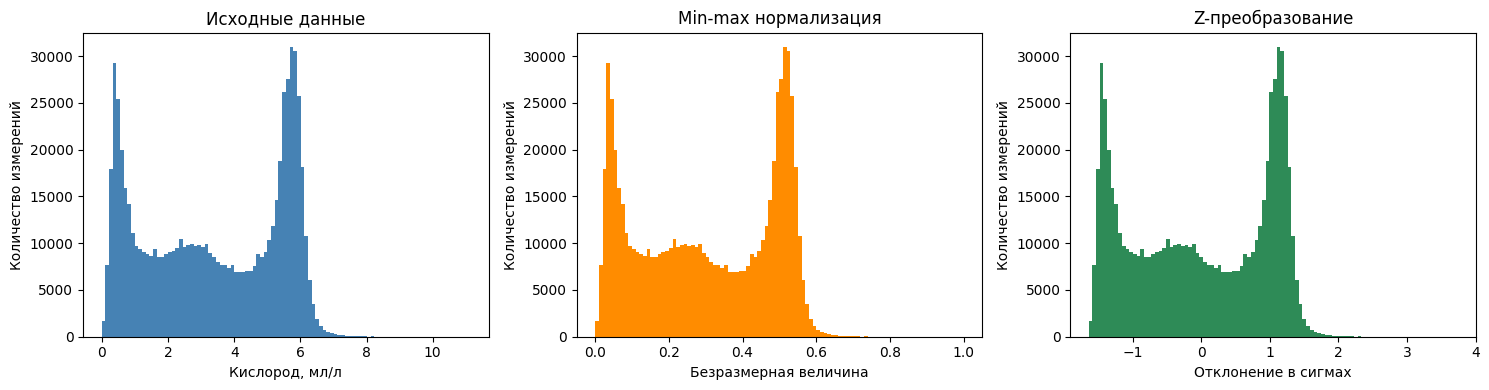

In [11]:
oxygen_minmax = (oxygen - oxygen.min()) / (oxygen.max() - oxygen.min())
oxygen_z = (oxygen - oxygen.mean()) / oxygen.std()

print("Исходные данные:   min =", round(oxygen.min(), 3),
      " max =", round(oxygen.max(), 3),
      " среднее =", round(oxygen.mean(), 3),
      " std =", round(oxygen.std(), 3))
print("После min-max:     min =", round(oxygen_minmax.min(), 3),
      " max =", round(oxygen_minmax.max(), 3),
      " среднее =", round(oxygen_minmax.mean(), 3),
      " std =", round(oxygen_minmax.std(), 3))
print("После Z-преобразования: min =", round(oxygen_z.min(), 3),
      " max =", round(oxygen_z.max(), 3),
      " среднее =", round(oxygen_z.mean(), 3),
      " std =", round(oxygen_z.std(), 3))

fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].hist(oxygen, bins=100, color="steelblue")
ax[0].set_title("Исходные данные")
ax[0].set_xlabel("Кислород, мл/л")

ax[1].hist(oxygen_minmax, bins=100, color="darkorange")
ax[1].set_title("Min-max нормализация")
ax[1].set_xlabel("Безразмерная величина")

ax[2].hist(oxygen_z, bins=100, color="seagreen")
ax[2].set_title("Z-преобразование")
ax[2].set_xlabel("Отклонение в сигмах")

for a in ax:
    a.set_ylabel("Количество измерений")

plt.tight_layout()
plt.show()

После нормализации форма графиков не изменилась, изменились диапазон и шкала измерения, так как мы рассматриваем одни и те же измерения. Нормализация нужна нам для того, чтобы в будущем мы могли сравнить кислород с другими величинами, и исследовать их на зависимость. Для выполнения моих дальнейших задач мне кажется более удобным способ измерения в сигмах (Z-преобразование), так как по нему можно увидеть, сколько значений оклоняются от нормы и на сколько.

### Sampling

In [12]:
import pandas as pd

sample_with = oxygen.sample(n=1000, replace=True, random_state=42)
sample_without = oxygen.sample(n=1000, replace=False, random_state=42)

comparison = pd.DataFrame({
    "Генеральная": [oxygen.mean(), oxygen.median(), oxygen.var(), oxygen.std()],
    "С возвращением": [sample_with.mean(), sample_with.median(), sample_with.var(), sample_with.std()],
    "Без возвращения": [sample_without.mean(), sample_without.median(), sample_without.var(), sample_without.std()],
}, index=["Среднее", "Медиана", "Дисперсия", "Ст. отклонение"])

print(comparison.round(3))

                Генеральная  С возвращением  Без возвращения
Среднее               3.392           3.388            3.434
Медиана               3.440           3.425            3.505
Дисперсия             4.298           4.387            4.198
Ст. отклонение        2.073           2.095            2.049


Среднее выборки с возвращением почти не отличается от генерального (3,392 − 3,388 = 0,004 мл/л). Между выборкой без возвращения и генеральной разница больше, но всё ещё не такая существенная (3,434 − 3,392 = 0,042 мл/л). Если сравнивать разницу со средним, то получается около 1% для 0,042 мл/л и примерно 0,1% для 0,004 мл/л. Такая разница объясняется обычной случайностью: в две выборки просто попали разные значения. Генеральная совокупность очень большая (696 201 значение), а выборка маленькая (1000), поэтому при выборке с возвращением одно и то же значение почти никогда не попадается дважды, и способ выборки практически не влияет на результат.

### Distribution description

Компонента 1: вес = 0.343, среднее = 5.667, ст. отклонение = 0.385
Компонента 2: вес = 0.195, среднее = 0.558, ст. отклонение = 0.258
Компонента 3: вес = 0.462, среднее = 2.903, ст. отклонение = 1.300


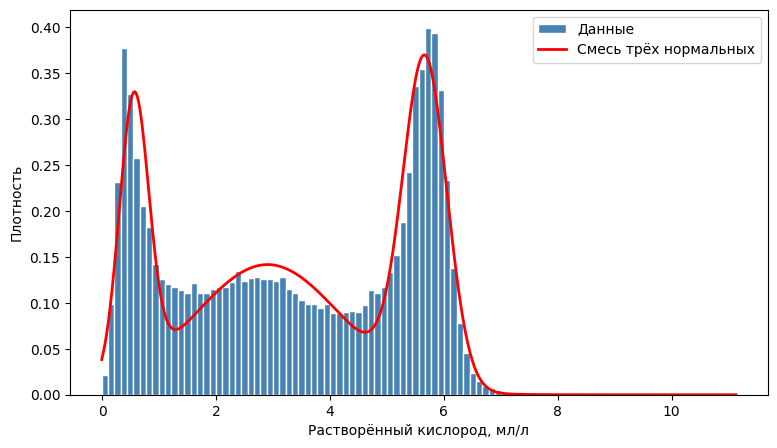

In [14]:
from sklearn.mixture import GaussianMixture
from scipy.stats import norm
import numpy as np

k = 3
gm = GaussianMixture(n_components=k, random_state=42)
gm.fit(oxygen.values.reshape(-1, 1))

weights = gm.weights_
means = gm.means_.flatten()
stds = np.sqrt(gm.covariances_.flatten())

for i in range(k):
    print(f"Компонента {i+1}: вес = {weights[i]:.3f}, среднее = {means[i]:.3f}, ст. отклонение = {stds[i]:.3f}")

x = np.linspace(oxygen.min(), oxygen.max(), 500)
density = sum(weights[i] * norm.pdf(x, means[i], stds[i]) for i in range(k))

plt.figure(figsize=(9, 5))
plt.hist(oxygen, bins=100, density=True, color="steelblue", edgecolor="white", label="Данные")
plt.plot(x, density, color="red", linewidth=2, label="Смесь трёх нормальных")
plt.xlabel("Растворённый кислород, мл/л")
plt.ylabel("Плотность")
plt.legend()
plt.show()

Распределение растворённого кислорода не является нормальным: на гистограмме видно три части - узкий пик около 0,5 мл/л, широкая полочка примерно от 1 до 5 мл/л и ещё один пик около 5,7 мл/л. Сначала я попробовала описать данные смесью двух нормальных распределений, но такая модель не описала левый пик. Поэтому распределение описано смесью трёх нормальных распределений:

f(x) = 0,195·N(0,558; 0,258) + 0,462·N(2,903; 1,300) + 0,343·N(5,667; 0,385),

где первое число в каждом слагаемом - вес компоненты (доля измерений), а в скобках - среднее и стандартное отклонение. Примерно 20 % измерений относятся к области низкого содержания кислорода, 46 % - к широкой промежуточной области и 34 % - к области высокого содержания. Красная кривая хорошо совпадает с гистограммой. Скорее всего, левый пик соответствует глубинным водам, где кислорода мало, а правый - поверхностным водам, насыщенным кислородом.

### Hypothesis testing

In [15]:
from scipy import stats

sample_test = oxygen.sample(n=1000, random_state=42)
stat, p_value = stats.shapiro(sample_test)

print(f"Статистика Шапиро–Уилка: {stat:.4f}")
print(f"p-value: {p_value:.2e}")

alpha = 0.05
if p_value < alpha:
    print("p-value < 0.05, отвергаем H0: распределение не нормальное")
else:
    print("p-value >= 0.05, нет оснований отвергнуть H0")

Статистика Шапиро–Уилка: 0.9073
p-value: 3.58e-24
p-value < 0.05, отвергаем H0: распределение не нормальное


Для проверки нормальности использован тест Шапиро–Уилка на случайной выборке из 1000 значений, так как этот тест рассчитан на выборки небольшого размера. Нулевая гипотеза H₀: кислород распределён нормально, альтернативная H₁: распределение не нормальное, уровень значимости α = 0,05. Получено W = 0,9073 и p-value ≈ 3,58·10⁻²⁴, что намного меньше 0,05, поэтому нулевая гипотеза отвергается, распределение растворённого кислорода не является нормальным. Это совпадает с результатами пункта 2.6, где мы описывали распределение смесью трёх нормальных распределений, а также отрицательным эксцессом (−1,48), найденным при описательной статистике.